# Tarea 2 – Parte 2: Evaluación y extracción estructurada

**Pregunta guía:** ¿qué tan fiel es el texto que producen el OCR y el ASR de la Parte 1, y se puede extraer de él información estructurada con un LLM local?

| Paso | Qué se hace | Sección |
| :--- | :--- | :--- |
| Muestra | 10 documentos y 10 clips del corpus de la Parte 1, con transcripción manual de referencia | 1 |
| Normalización | Un solo criterio para referencias y salidas automáticas | 2 |
| Línea base | CER de PaddleOCR y WER de faster-whisper `small` | 3 |
| Comparación | EasyOCR y Parakeet en las mismas muestras, y casos difíciles | 4 |
| LLM | Extracción en JSON de los 48 archivos con Qwen2.5 local y auditoría humana de 20 | 5 |
| Decisión | Tabla comparativa, modelo elegido y reflexión | 6 |

**Privacidad.** Igual que en la Parte 1, este notebook solo muestra textos seudonimizados y conteos. Las referencias manuales de las entrevistas tienen los nombres reales de los niños: se guardan en `datos/raw/referencias/` (fuera de Git) y se seudonimizan antes de escribirlas en los CSV. Las métricas se calculan sobre los textos sin seudonimizar, para que un nombre mal escrito por el ASR cuente como error. Solo se publican los números.

In [1]:
import gc
import json
import os
import random
import re
import time
import unicodedata
import warnings
from datetime import date
from importlib.metadata import version
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import jiwer
import pandas as pd
import plotly.express as px
import plotly.io as pio
import psutil
import truststore
from rapidfuzz import fuzz

# Valida HTTPS con los certificados del sistema operativo (el antivirus intercepta HTTPS)
truststore.inject_into_ssl()

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 950
pio.templates.default = "plotly_white"
pio.templates["plotly_white"].layout.separators = ", "   # coma decimal en los ejes
pd.set_option("display.max_colwidth", 110)

DATOS, MODELOS = Path("datos"), Path("modelos")
RAW = DATOS / "raw"
REF_DIR = RAW / "referencias"     # transcripciones manuales con nombres reales (fuera de Git)
EVAL_DIR = RAW / "evaluacion"     # salidas crudas de los modelos de esta parte (fuera de Git)
FECHA = date.today().isoformat()
PROC = psutil.Process()

docs = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
audios = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)
print(f"Fecha de evaluación: {FECHA} · corpus de la Parte 1: {len(docs)} documentos y {len(audios)} clips")
print(" · ".join(f"{p} {version(p)}" for p in ["jiwer", "paddleocr", "easyocr", "faster-whisper", "onnx-asr", "llama_cpp_python"]))

Fecha de evaluación: 2026-10-25 · corpus de la Parte 1: 25 documentos y 23 clips
jiwer 4.0.0 · paddleocr 3.7.0 · easyocr 1.7.2 · faster-whisper 1.2.1 · onnx-asr 0.12.0 · llama_cpp_python 0.3.2


## 1. Muestra de evaluación

La muestra sale del corpus de la Parte 1, sin datos nuevos, y se eligió antes de correr cualquier modelo de esta parte.

- **10 documentos**, sorteados por tipo con una semilla fija (`random.Random(42)`): 3 impresos, 3 fotos de celular y 4 manuscritos. Los manuscritos llevan uno más porque son el caso más difícil y el más variado.
- **10 clips de dos fuentes con condiciones de grabación distintas:**
  - Las **5 entrevistas más cortas**: conversación espontánea entre la profesora y un niño de unos 5 años, grabada con el celular en el jardín. Se eligieron por duración porque cada minuto hay que transcribirlo a mano.
  - **5 frases de OpenSLR 73**, sorteadas con la misma semilla: lectura en voz alta de un adulto, grabada en silencio.
  - Los dos podcasts (8 y 20 min) quedan fuera por su duración.

In [2]:
rng = random.Random(42)
CUPO = {"impreso": 3, "foto": 3, "manuscrito": 4}
muestra_docs = [i for tipo, k in CUPO.items()
                for i in sorted(rng.sample(sorted(docs.loc[docs["tipo"] == tipo, "id"]), k))]
entrevistas = sorted(audios[audios["fuente"] == "Entrevista propia"].nsmallest(5, "duracion_seg")["id"])
lecturas = sorted(rng.sample(sorted(audios.loc[audios["fuente"] == "OpenSLR 73", "id"]), 5))
muestra_audios = entrevistas + lecturas

CONDICION = {"Entrevista propia": "entrevista (habla espontánea de niños, celular, aula)",
             "OpenSLR 73": "lectura (adulto, micrófono, silencio)"}
m_docs = docs.set_index("id").loc[muestra_docs, ["tipo"]]
m_audios = audios.set_index("id").loc[muestra_audios, ["fuente", "duracion_seg", "n_hablantes"]]
m_audios["condicion"] = m_audios["fuente"].map(CONDICION)
print(f"Documentos: {m_docs['tipo'].value_counts().to_dict()}")
print(f"Clips: {len(m_audios)} ({m_audios['duracion_seg'].sum() / 60:.1f} min)")
m_audios

Documentos: {'manuscrito': 4, 'impreso': 3, 'foto': 3}
Clips: 10 (8.9 min)


,fuente,duracion_seg,n_hablantes,condicion
id,,,,
clip_004,Entrevista propia,123.8,2,"entrevista (habla espontánea de niños, celular, aula)"
clip_007,Entrevista propia,86.1,2,"entrevista (habla espontánea de niños, celular, aula)"
clip_008,Entrevista propia,124.0,2,"entrevista (habla espontánea de niños, celular, aula)"
clip_009,Entrevista propia,116.6,2,"entrevista (habla espontánea de niños, celular, aula)"
clip_010,Entrevista propia,42.7,2,"entrevista (habla espontánea de niños, celular, aula)"
clip_012,OpenSLR 73,7.0,1,"lectura (adulto, micrófono, silencio)"
clip_013,OpenSLR 73,9.6,1,"lectura (adulto, micrófono, silencio)"
clip_018,OpenSLR 73,7.9,1,"lectura (adulto, micrófono, silencio)"
clip_020,OpenSLR 73,9.7,1,"lectura (adulto, micrófono, silencio)"


### 1.1 Transcripciones manuales de referencia

La estudiante transcribió a mano los 20 archivos: un `.txt` por archivo en `datos/raw/referencias/{id}.txt`, en UTF-8. El método fue distinto según el tipo:

| Archivos | Cómo se hizo la referencia |
| :--- | :--- |
| `impreso1`, `impreso2` | La capa de texto del PDF original de las bases (SEACE), que la estudiante comparó con la imagen y corrigió donde no coincidía |
| `impreso6` | Esa página del PDF es un escaneo: solo el encabezado viene de la capa de texto y el cuerpo se transcribió a mano |
| `foto2`, `foto5`, `foto7` | A mano, mirando la foto. En `foto5` y `foto7` se transparentan del reverso unos nombres espejados, que no se transcribieron: no son texto de la página y son datos personales |
| `manuscrito2`, `3`, `6`, `7` | A mano y de forma literal, sin modernizar la ortografía |
| 5 entrevistas | A mano y desde cero, escuchando el audio sin mirar el texto del ASR: una intervención por línea con la etiqueta `H1` o `H2`. Los nombres se escribieron como suenan |
| 5 frases de OpenSLR | De oído, sin mirar la transcripción oficial del corpus |

Las referencias se cargan sin tocar, y para los CSV se seudonimizan con la misma revisión manual de la Parte 1 (`datos/raw/seudonimizacion/revision.csv`). En esta parte se le agregaron:

- el nombre de una profesora que aparece en una referencia;
- tres formas de nombres de niños que escribieron los ASR alternativos;
- por decisión de la estudiante, el nombre del colegio que menciona un niño en `clip_010`, que pasa a `[INSTITUCION]`. Junto con el seudónimo del niño, el colegio podría ayudar a identificarlo. El ASR de la Parte 1 no lo había transcrito, así que nunca se publicó.

Al pasar a los CSV, las etiquetas `H1`/`H2` pasan al formato `[HABLANTE_1]`/`[HABLANTE_2]` de `texto_asr`. La numeración es la de la estudiante, no la de la diarización.

In [3]:
PATRONES = {
    "DNI": r"(?i)\bD\.?\s?N\.?\s?I\.?\s*(?:N[°ºo.]*\s*)?:?\s*\d{8}\b",
    "CELULAR": r"(?<!\d)9\d{2}[\s-]?\d{3}[\s-]?\d{3}(?!\d)",
    "CORREO": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",
    "RUC": r"(?<!\d)10\d{9}(?!\d)",
}
revision = pd.read_csv(RAW / "seudonimizacion" / "revision.csv", keep_default_na=False)
personas = revision[(revision["decision"] == "reemplazar") & revision["tipo"].isin(["PERSONA", "INSTITUCION"])]
MANTENER = set(revision.loc[revision["decision"] == "mantener", "entidad"])


def seudonimizar(texto, reemplazos, parecido=80):
    """La misma función de 01_extraccion.ipynb (sección 6): primero coincidencias exactas y después
    aproximadas (rapidfuzz ≥ 80), estas solo para nombres de 5 letras o más."""
    salida = texto
    for exacto in (True, False):
        for nombre, seudonimo in reemplazos.items():
            if not exacto and len(nombre) < 5:
                continue
            k = len(nombre.split())
            palabras = re.findall(r"\w+|\W+", salida)
            idx = [i for i, p in enumerate(palabras) if re.match(r"\w", p)]
            cambios, j = [], 0
            while j <= len(idx) - k:
                a, b = idx[j], idx[j + k - 1]
                tramo = "".join(palabras[a:b + 1]).lower()
                if (tramo == nombre.lower()) if exacto else (fuzz.ratio(tramo, nombre.lower()) >= parecido):
                    cambios.append((a, b))
                    j += k
                else:
                    j += 1
            for a, b in reversed(cambios):
                palabras[a:b + 1] = [seudonimo]
            salida = "".join(palabras)
    return salida


def nombres_para(ident):
    "Nombres cuyo ámbito incluye este archivo; primero los más largos."
    aplica = personas[[a == "todos" or ident in a.split(";") for a in personas["ambito"]]]
    return dict(sorted(zip(aplica["entidad"], aplica["seudonimo"]), key=lambda kv: -len(kv[0])))


def publicable(texto, ident):
    "Texto listo para publicar: datos numéricos y correos con su marca, nombres con su seudónimo."
    for tipo, patron in PATRONES.items():
        texto = re.sub(patron, lambda m: m.group() if m.group() in MANTENER else f"[{tipo}]", texto)
    return seudonimizar(texto, nombres_para(ident))


# Etiqueta de hablante de las referencias: al inicio de línea con «:» o tabulador, o «H1:» a mitad de línea
ETIQUETA = r"(?m)(?:^[ \t]*[Hh](\d)\d?[ \t]*[:\t]|(?<!\w)[Hh](\d)\d?[ \t]*:)"


def a_marcas(texto):
    "Etiquetas H1/H2 de la referencia -> [HABLANTE_1]/[HABLANTE_2]."
    texto = re.sub(ETIQUETA, lambda m: f" [HABLANTE_{m.group(1) or m.group(2)}] ", texto)
    return " ".join(texto.split())


referencias = {i: (REF_DIR / f"{i}.txt").read_text(encoding="utf-8") for i in muestra_docs + muestra_audios}
vacias = [i for i, t in referencias.items() if not t.strip()]
assert not vacias, f"Faltan referencias: {vacias}"

docs["texto_referencia"] = [publicable(referencias[i], i) if i in referencias else "" for i in docs["id"]]
audios["texto_referencia"] = [publicable(a_marcas(referencias[i]), i) if i in referencias else "" for i in audios["id"]]
docs.to_csv(DATOS / "documentos.csv", index=False)
audios.to_csv(DATOS / "transcripciones.csv", index=False)

# Comprobación: ningún nombre marcado para reemplazar sobrevive en las referencias publicadas
quedan = [(i, n) for d in (docs, audios) for i, t in zip(d["id"], d["texto_referencia"]) for n in nombres_para(i)
          if t and re.search(rf"\b{re.escape(n)}\b", t, re.I)]
tamano = pd.DataFrame({"id": list(referencias), "palabras": [len(t.split()) for t in referencias.values()],
                       "caracteres": [len(" ".join(t.split())) for t in referencias.values()]})
print(f"Referencias: {len(referencias)} · {tamano['palabras'].sum()} palabras · nombres que siguen en el texto: {len(quedan)}")
print(f"texto_referencia completo en documentos.csv: {(docs['texto_referencia'] != '').sum()} y "
      f"en transcripciones.csv: {(audios['texto_referencia'] != '').sum()}")
tamano.set_index("id").T

Referencias: 20 · 3909 palabras · nombres que siguen en el texto: 0
texto_referencia completo en documentos.csv: 10 y en transcripciones.csv: 10


id,impreso1,impreso2,impreso6,foto2,foto5,foto7,manuscrito2,manuscrito3,manuscrito6,manuscrito7,clip_004,clip_007,clip_008,clip_009,clip_010,clip_012,clip_013,clip_018,clip_020,clip_021
palabras,286,450,345,330,479,475,219,97,55,51,244,212,289,191,85,22,18,20,21,20
caracteres,1834,3035,2476,2250,2886,2957,1264,573,372,348,1317,1010,1470,1046,507,95,91,95,120,84


### 1.2 Configuraciones de los modelos

Todas las configuraciones quedan fijadas aquí, antes de calcular cualquier métrica de esta parte, y no se cambian después de ver los resultados. Se guardan en `modelos/configuracion_evaluacion.json`.

- **Línea base sin personalización.** PaddleOCR y faster-whisper usan sus modelos preentrenados, sin ajuste fino ni diccionarios propios. Las salidas de PaddleOCR son las de la Parte 1. Su único cambio respecto a los valores por defecto es un límite de 3000 px para el lado mayor de la imagen, que se puso por memoria (con 4000 px los manuscritos grandes agotaban los 7 GB de RAM) y no por precisión.
- **ASR en igualdad de condiciones.** faster-whisper `small` usa las mismas opciones que large-v3-turbo en la Parte 1: español fijo, `beam_size=5` y el mismo VAD. Así la diferencia entre los dos se debe solo al tamaño del modelo. Turbo entra a la tabla como tercer punto de comparación, sin volver a ejecutarlo.
- **Alternativos con sus valores por defecto**, salvo lo que exige la máquina:
  - **EasyOCR** reduce la imagen a 1600 px solo para *detectar* las líneas. Lee el texto sobre la imagen original. Con el valor por defecto, 2560 px, un manuscrito grande pide más RAM de la que hay.
  - **Parakeet** solo acepta tramos cortos, así que corre con el VAD Silero de `onnx-asr`, que corta el audio en tramos de voz.

**Por qué estos alternativos.** Tesseract no está instalado y en Windows necesita un instalador aparte, fuera de `pip`. EasyOCR se instala con `pip` y usa una arquitectura distinta de la de PaddleOCR: el detector CRAFT y un reconocedor CRNN. Parakeet TDT 0.6B v3 (NVIDIA, CC BY 4.0) es un ASR multilingüe que cubre el español, de otra familia que Whisper (FastConformer con decodificador TDT). Su versión ONNX cuantizada en int8 corre en CPU con unos 1,5 GB de RAM. MMS-1B, con 1000 millones de parámetros (unos 4 GB en float32), no cabe cómodo en los 7 GB de RAM de la laptop, que comparte con el resto del entorno.

In [4]:
OCR_PARTE1 = json.loads((RAW / "documentos" / "ocr" / f"{muestra_docs[0]}.json").read_text(encoding="utf-8"))
ASR_PARTE1 = json.loads((RAW / "audio" / "salidas" / f"{muestra_audios[0]}.json").read_text(encoding="utf-8"))
OPCIONES_WHISPER = ASR_PARTE1["opciones"]   # las mismas de la Parte 1
CONFIG = {
    "PaddleOCR": {"rol": "OCR base", "modelo": " + ".join(OCR_PARTE1["modelos"]), "version": OCR_PARTE1["paddleocr"],
                  "opciones": OCR_PARTE1["opciones"], "origen": "salidas de 01_extraccion.ipynb (sección 3)"},
    "EasyOCR": {"rol": "OCR alternativo", "modelo": "craft_mlt_25k + latin_g2", "version": version("easyocr"),
                "opciones": {"lang_list": ["es"], "gpu": False, "canvas_size": 1600}},
    "faster-whisper small": {"rol": "ASR base", "modelo": "Systran/faster-whisper-small", "version": version("faster-whisper"),
                             "opciones": {"device": "cpu", "compute_type": "int8", **OPCIONES_WHISPER}},
    "Parakeet TDT 0.6B v3": {"rol": "ASR alternativo", "modelo": "istupakov/parakeet-tdt-0.6b-v3-onnx", "version": version("onnx-asr"),
                             "opciones": {"quantization": "int8", "vad": "silero (valores por defecto de onnx-asr)"}},
    "faster-whisper large-v3-turbo": {"rol": "ASR de la Parte 1", "modelo": ASR_PARTE1["modelo"], "version": version("faster-whisper"),
                                      "opciones": {"device": "cpu", "compute_type": "int8", **OPCIONES_WHISPER},
                                      "origen": "salidas de 01_extraccion.ipynb (sección 4)"},
    "Qwen2.5-1.5B-Instruct": {"rol": "LLM de extracción", "modelo": "Qwen/Qwen2.5-1.5B-Instruct-GGUF (q4_k_m)",
                              "version": version("llama_cpp_python"),
                              "opciones": {"n_ctx": 4096, "temperature": 0, "seed": 42, "max_tokens": 400,
                                           "max_caracteres_entrada": 8000, "salida": "JSON con esquema"}},
}
(MODELOS / "configuracion_evaluacion.json").write_text(json.dumps({"fecha": FECHA, "modelos": CONFIG}, ensure_ascii=False, indent=1),
                                                       encoding="utf-8")
pd.DataFrame(CONFIG).T[["rol", "modelo", "version"]]

,rol,modelo,version
PaddleOCR,OCR base,PP-OCRv6_medium_det + PP-OCRv6_medium_rec,3.7.0
EasyOCR,OCR alternativo,craft_mlt_25k + latin_g2,1.7.2
faster-whisper small,ASR base,Systran/faster-whisper-small,1.2.1
Parakeet TDT 0.6B v3,ASR alternativo,istupakov/parakeet-tdt-0.6b-v3-onnx,0.12.0
faster-whisper large-v3-turbo,ASR de la Parte 1,mobiuslabsgmbh/faster-whisper-large-v3-turbo,1.2.1
Qwen2.5-1.5B-Instruct,LLM de extracción,Qwen/Qwen2.5-1.5B-Instruct-GGUF (q4_k_m),0.3.2


## 2. Criterio de normalización

Una sola función, `normalizar`, se aplica igual a las referencias y a todas las salidas automáticas antes de calcular CER y WER. Así solo cuentan los errores de contenido:

1. Se quitan las marcas de hablante: `[HABLANTE_X]` de la diarización y `H1:`/`H2:` de las referencias. El WER mide las palabras, no quién las dice.
2. Todo pasa a minúsculas, en forma Unicode NFC.
3. La puntuación y los símbolos pasan a ser espacios, y los espacios y saltos de línea seguidos se juntan en uno.

**Se conservan** las tildes y la ñ, porque en español cambian la palabra («esta» y «está»), y también los números tal como se escribieron. Si el modelo pone «13» y la referencia dice «trece», es un error: la referencia se escribió como se ve o se oye, sin convertir números.

**CER** = (sustituciones + borrados + inserciones de caracteres) / caracteres de la referencia, sobre el texto normalizado, con espacios. **WER** es lo mismo pero por palabras. El valor de un grupo de archivos se calcula sumando los errores de todos y dividiendo entre el total de la referencia, de modo que un archivo largo pesa más que uno corto. No es el promedio de los porcentajes de cada archivo.

In [5]:
def normalizar(texto):
    texto = re.sub(r"\[HABLANTE_\d+\]", " ", texto)
    texto = re.sub(ETIQUETA, " ", texto)
    texto = unicodedata.normalize("NFC", texto).lower()
    texto = re.sub(r"[^\w\s]|_", " ", texto)
    return " ".join(texto.split())


def medir(refs, hyps, unidad):
    "CER (unidad='caracteres') o WER (unidad='palabras') de una lista de pares, con el detalle de errores."
    refs, hyps = [normalizar(r) for r in refs], [normalizar(h) for h in hyps]
    o = jiwer.process_characters(refs, hyps) if unidad == "caracteres" else jiwer.process_words(refs, hyps)
    n = o.hits + o.substitutions + o.deletions
    return {"tasa": o.substitutions / n + o.deletions / n + o.insertions / n, "sustituciones": o.substitutions,
            "borrados": o.deletions, "inserciones": o.insertions, f"{unidad}_ref": n}


print(normalizar("[HABLANTE_1] ¿Está   bien,\nLa Lista N° 13?"))
print(normalizar("H2: ¡Sí! Está bien… la lista nº 13"))

está bien la lista n 13
sí está bien la lista nº 13


**Control de calidad de las referencias de audio.** Las frases de OpenSLR traen una transcripción oficial, que la estudiante no miró. Comparar las dos mide cuánto difiere una transcripción manual de otra. Ese es el «ruido» de la referencia: con 10 clips, una diferencia de WER entre modelos más chica que ese ruido no se puede tomar como real.

In [6]:
oficial = pd.read_csv(RAW / "audio" / "openslr73" / "openslr73_transcripciones.tsv", sep="\t").set_index("file_id")["transcripcion"]
archivo_de = audios.set_index("id")["archivo_audio"].map(lambda r: Path(r).stem)
control = pd.DataFrame([{"id": i, **medir([oficial[archivo_de[i]]], [referencias[i]], "palabras")} for i in lecturas])
total = medir([oficial[archivo_de[i]] for i in lecturas], [referencias[i] for i in lecturas], "palabras")
print(f"WER de la referencia manual frente a la oficial de OpenSLR: {total['tasa']:.1%} "
      f"({total['sustituciones'] + total['borrados'] + total['inserciones']} diferencias en {total['palabras_ref']} palabras)")
for i in lecturas:   # frases leídas de guion, sin datos personales
    a, b = normalizar(oficial[archivo_de[i]]).split(), normalizar(referencias[i]).split()
    if a != b:
        print(f"  {i}: oficial «{oficial[archivo_de[i]]}»\n  {' ' * len(i)}  manual  «{a_marcas(referencias[i]).replace('[HABLANTE_1] ', '')}»")

WER de la referencia manual frente a la oficial de OpenSLR: 7.0% (7 diferencias en 100 palabras)
  clip_012: oficial «Ya ví las fotos que subiste ayer a la red, te ves muy bien, te queda muy bien el color rojo»
            manual  «ya vi las fotos que subiste ayer a la red, te ves muy bien, te queda muy bien el color rojo»
  clip_013: oficial «La película de King Kong ha tenido varias versiones, la primera se filmó en el año mil novecientos treinta y ocho.»
            manual  «la película de king Kong ha tenido varias versiones, la primera se filmó en el año 1938»
  clip_021: oficial «El día de mañana hay un concierto de pop a las once de la noche en la sala Caracol»
            manual  «el día de mañana hay un concierto de Pop a las 11 de la noche en la sala caracol»


**Lectura.** Las 7 diferencias son de convención y no de oído:

- La estudiante escribió los números en cifras («1938», «11») y el corpus los escribe en letras («mil novecientos treinta y ocho», «once»). Solo el año ya suma 5 diferencias.
- La transcripción oficial pone una tilde de más («ví»).

Ninguna palabra está mal oída. La referencia manual es confiable, pero el WER depende de cómo se escriben los números: un ASR que pone «1938» acierta con esta referencia y fallaría con la oficial. Por eso la convención se fija una sola vez, la de la referencia manual, y no se cambia según el modelo.

## 3. Línea base

Cada modelo corre sobre la muestra a través de `correr`, que guarda la salida cruda de cada archivo en `datos/raw/evaluacion/<modelo>/` (fuera de Git, porque tiene nombres reales) y no repite lo que ya está guardado. Para cada archivo se miden los segundos de inferencia, y para cada modelo, los segundos de carga. La RAM se mide aparte, en la sección 6, en un proceso nuevo para cada modelo: en este, la memoria que deja libre un modelo se mezcla con la que toma el siguiente.

In [7]:
def correr(nombre, ids, cargar, procesar):
    "Corre un modelo sobre ids con caché por archivo; solo carga el modelo si falta alguna salida."
    carpeta = EVAL_DIR / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    faltan = [i for i in ids if not (carpeta / f"{i}.json").exists()]
    if faltan:
        t0 = time.perf_counter()
        modelo = cargar()
        (carpeta / "_carga.json").write_text(json.dumps({"segundos_carga": round(time.perf_counter() - t0, 1)}))
        for i in faltan:
            t0 = time.perf_counter()
            texto = procesar(modelo, i)
            salida = {"id": i, "texto": texto, "segundos": round(time.perf_counter() - t0, 2), "fecha": FECHA}
            (carpeta / f"{i}.json").write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")
        del modelo
        gc.collect()
    salidas = {i: json.loads((carpeta / f"{i}.json").read_text(encoding="utf-8")) for i in ids}
    return salidas, json.loads((carpeta / "_carga.json").read_text())


def tabla(salidas, modelo, unidad, base):
    "Métrica por archivo de un modelo (base: DataFrame con la columna de grupo y la duración si es audio)."
    filas = [{"id": i, "modelo": modelo, **medir([referencias[i]], [s["texto"]], unidad), "segundos": s["segundos"]}
             for i, s in salidas.items()]
    return base.join(pd.DataFrame(filas).set_index("id"))


def resumen(t, grupo):
    "Métrica agregada (errores totales / referencia total) por modelo y grupo."
    unidad = "caracteres_ref" if "caracteres_ref" in t else "palabras_ref"
    errores = t["sustituciones"] + t["borrados"] + t["inserciones"]
    return (t.assign(errores=errores).groupby(["modelo", grupo])[["errores", unidad]].sum()
             .pipe(lambda g: g["errores"] / g[unidad]).unstack(grupo))

### 3.1 OCR: PaddleOCR sin personalización

El texto evaluado es la salida cruda de PaddleOCR en la Parte 1: las líneas en el orden en que las devuelve el detector, sin la limpieza ni la seudonimización. Los segundos son los que midió la Parte 1 para cada imagen.

In [8]:
def leer_paddle(i):
    j = json.loads((RAW / "documentos" / "ocr" / f"{i}.json").read_text(encoding="utf-8"))
    return {"id": i, "texto": "\n".join(l["texto"] for l in j["lineas"]), "segundos": j["segundos"]}


salidas_ocr = {"PaddleOCR": {i: leer_paddle(i) for i in muestra_docs}}
cer = tabla(salidas_ocr["PaddleOCR"], "PaddleOCR", "caracteres", m_docs)
print(f"CER de PaddleOCR en los 10 documentos: {medir([referencias[i] for i in muestra_docs], [salidas_ocr['PaddleOCR'][i]['texto'] for i in muestra_docs], 'caracteres')['tasa']:.1%}")
cer[["tipo", "tasa", "sustituciones", "borrados", "inserciones", "caracteres_ref", "segundos"]].round(3)

CER de PaddleOCR en los 10 documentos: 9.6%


,tipo,tasa,sustituciones,borrados,inserciones,caracteres_ref,segundos
id,,,,,,,
impreso1,impreso,0.001,0,0,2,1804,20.0
impreso2,impreso,0.000,0,0,0,2973,26.3
impreso6,impreso,0.097,74,73,88,2424,24.5
foto2,foto,0.005,6,4,1,2196,16.3
foto5,foto,0.011,7,1,24,2816,19.2
foto7,foto,0.004,6,1,5,2869,18.9
manuscrito2,manuscrito,0.701,482,194,176,1215,38.4
manuscrito3,manuscrito,0.519,91,161,40,563,35.8
manuscrito6,manuscrito,0.194,41,23,6,361,46.6


**Lectura.** PaddleOCR casi no se equivoca en las páginas limpias. `impreso1` e `impreso2` quedan en 0,1 % o menos, y ninguna de las tres fotos de celular pasa del 1,1 %. Un detalle: la referencia de los dos primeros impresos viene de la capa de texto del mismo PDF, así que coincide letra por letra con lo que muestra la página. `impreso6`, que dentro del PDF es un escaneo, ya sube a 9,7 %. Los manuscritos van del 19 % al 70 %. El sistema es útil para buscar texto en impresos y fotos, pero no en manuscritos.

### 3.2 ASR: faster-whisper `small` en CPU

Se ejecuta aquí sobre los 10 clips. El **factor de tiempo real** (RTF) es el tiempo de inferencia dividido entre la duración del audio, e incluye el VAD. Un RTF de 0,5 significa que un minuto de audio se transcribe en 30 s.

In [9]:
from faster_whisper import WhisperModel
from faster_whisper.audio import decode_audio

SR = 16_000
ruta_audio = audios.set_index("id")["archivo_audio"]


def cargar_audio(ruta):
    "Igual que en la Parte 1: PyAV, y libsndfile para los .ogg con el último paquete dañado."
    try:
        return decode_audio(str(ruta), sampling_rate=SR)
    except Exception:
        import soundfile as sf
        from scipy.signal import resample_poly
        x, sr = sf.read(str(ruta), dtype="float32")
        x = x.mean(axis=1) if x.ndim > 1 else x
        return resample_poly(x, SR, sr).astype("float32")


def transcribir_whisper(modelo, i):
    segmentos, _ = modelo.transcribe(cargar_audio(ruta_audio[i]), **OPCIONES_WHISPER)
    return " ".join(s.text.strip() for s in segmentos)


salidas_asr, cargas = {}, {}
salidas_asr["faster-whisper small"], cargas["faster-whisper small"] = correr(
    "faster-whisper-small", muestra_audios,
    lambda: WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=min(8, os.cpu_count() or 4)),
    transcribir_whisper)
wer = tabla(salidas_asr["faster-whisper small"], "faster-whisper small", "palabras", m_audios[["condicion", "duracion_seg"]])
wer["rtf"] = wer["segundos"] / wer["duracion_seg"]
total = medir([referencias[i] for i in muestra_audios], [salidas_asr["faster-whisper small"][i]["texto"] for i in muestra_audios], "palabras")
print(f"WER de faster-whisper small en los 10 clips: {total['tasa']:.1%} · RTF: "
      f"{wer['segundos'].sum() / wer['duracion_seg'].sum():.2f} · carga: {cargas['faster-whisper small']}")
wer[["condicion", "tasa", "sustituciones", "borrados", "inserciones", "palabras_ref", "rtf"]].round(3)

WER de faster-whisper small en los 10 clips: 17.2% · RTF: 0.33 · carga: {'segundos_carga': 3.0}


,condicion,tasa,sustituciones,borrados,inserciones,palabras_ref,rtf
id,,,,,,,
clip_004,"entrevista (habla espontánea de niños, celular, aula)",0.271,30,24,5,218,0.303
clip_007,"entrevista (habla espontánea de niños, celular, aula)",0.237,18,1,27,194,0.380
clip_008,"entrevista (habla espontánea de niños, celular, aula)",0.115,13,11,5,252,0.377
clip_009,"entrevista (habla espontánea de niños, celular, aula)",0.141,16,6,2,170,0.268
clip_010,"entrevista (habla espontánea de niños, celular, aula)",0.182,11,1,2,77,0.303
clip_012,"lectura (adulto, micrófono, silencio)",0.000,0,0,0,21,0.509
clip_013,"lectura (adulto, micrófono, silencio)",0.000,0,0,0,17,0.370
clip_018,"lectura (adulto, micrófono, silencio)",0.053,0,1,0,19,0.451
clip_020,"lectura (adulto, micrófono, silencio)",0.000,0,0,0,20,0.382


**Lectura.** `small` transcribe casi sin errores las frases leídas: 1 error en 96 palabras. En las entrevistas, en cambio, falla en casi 1 de cada 5 palabras, con un WER de entre el 11 % y el 28 % según el clip. Corre a un RTF de 0,33: transcribe un minuto de audio en unos 20 s.

## 4. Comparación de modelos en las mismas 10 muestras

### 4.1 Documentos: PaddleOCR frente a EasyOCR

In [10]:
import easyocr

RUTA_IMG = docs.set_index("id")["archivo"]
salidas_ocr["EasyOCR"], cargas["EasyOCR"] = correr(
    "easyocr", muestra_docs,
    lambda: easyocr.Reader(["es"], gpu=False, verbose=False),
    lambda modelo, i: "\n".join(t for _, t, _ in modelo.readtext(str(RUTA_IMG[i]), canvas_size=1600)))
cer = pd.concat([tabla(salidas_ocr[m], m, "caracteres", m_docs) for m in salidas_ocr])
TIPOS = list(CUPO)
cer_tipo = resumen(cer, "tipo").loc[list(salidas_ocr), TIPOS]   # primero la línea base
cer_tipo["global"] = [medir([referencias[i] for i in muestra_docs], [salidas_ocr[m][i]["texto"] for i in muestra_docs],
                            "caracteres")["tasa"] for m in cer_tipo.index]
print(f"EasyOCR: carga {cargas['EasyOCR']}")
cer_tipo.style.format("{:.1%}")

EasyOCR: carga {'segundos_carga': 2.9}


tipo,impreso,foto,manuscrito,global
modelo,,,,
PaddleOCR,3.3%,0.7%,55.8%,9.6%
EasyOCR,5.7%,8.5%,72.0%,16.3%


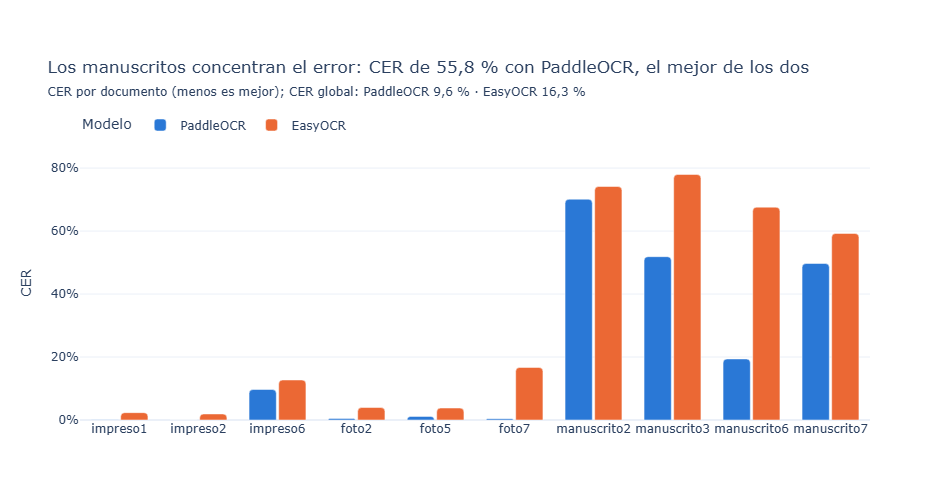

In [11]:
# Paleta categórica de la Parte 1, en orden fijo: el color sigue al modelo en todos los gráficos
AZUL, NARANJA, AQUA, TINTA_2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
COLOR = {"PaddleOCR": AZUL, "EasyOCR": NARANJA,
         "faster-whisper small": AZUL, "Parakeet TDT 0.6B v3": NARANJA, "faster-whisper large-v3-turbo": AQUA}
pct = lambda x: f"{100 * x:.1f}".replace(".", ",") + " %"

g = cer.reset_index()
mejor = cer_tipo["global"].idxmin()
fig4 = px.bar(g, x="id", y="tasa", color="modelo", barmode="group", color_discrete_map=COLOR,
              category_orders={"id": muestra_docs, "modelo": list(salidas_ocr)},
              hover_data={"tipo": True, "tasa": ":.1%", "segundos": ":.1f"},
              labels={"id": "", "tasa": "CER", "modelo": "Modelo"})
fig4.update_yaxes(tickformat=".0%", range=[0, 1.12 * g["tasa"].max()])
fig4.update_layout(barcornerradius=4, bargap=0.25, bargroupgap=0.08, legend=dict(orientation="h", y=1.02, x=0, yanchor="bottom"),
                   margin=dict(t=145), title=dict(
    text=f"Los manuscritos concentran el error: CER de {pct(cer_tipo.loc[mejor, 'manuscrito'])} con {mejor}, el mejor de los dos",
    subtitle=dict(text="CER por documento (menos es mejor); CER global: " +
                       " · ".join(f"{m} {pct(v)}" for m, v in cer_tipo["global"].items()))))
fig4.show()